# Введение в Matplotlib
<div style="text-align:right;">Гейне М.А. <span style="font-style: italic;font-weight: bold;">(geine@bmstu.ru)</span></div>

Цель — выбрать подходящий вид графика, подписать данные и оси, разместить несколько областей на рисунке и сохранить результат в файл. Это продолжение работы с массивами NumPy и переход к визуализации таблиц pandas.

**Основной маршрут S7:** разметка через `subplot`, линейный график и его оформление, `scatter`, `bar`, `hist`, явная работа с `Figure` и `Axes`, построение из pandas и сохранение рисунка. Кодовые ячейки маршрута отмечены тегом `core` и образуют самостоятельную последовательность при запуске сверху вниз.

**Дополнительно:** `GridSpec`, подробные варианты легенд и цветовых карт, горизонтальные и вертикальные линии, трёхмерные поверхности и контурные графики. Они остаются справочником.

Matplotlib создаёт рисунки из данных NumPy и pandas. `Figure` — весь рисунок, `Axes` — область построения, а `Axis` — отдельная координатная ось. В интерфейсе `pyplot` команды работают с текущей областью; при явной работе с объектами область передаётся через переменную `ax`.

В тетради выбран `%matplotlib inline`: графики выводятся как статические изображения. Масштабирование мышью и вращение 3D-поверхности зависят от другого backend и здесь не требуются.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
%matplotlib inline

# Повторяемые данные для всех случайных примеров этой тетради
rng = np.random.default_rng(2026)

Необязательный вывод графика в отдельном окне: `%matplotlib qt` требует установленного Qt backend и графической среды. Для основного маршрута достаточно `inline`.

In [2]:
# %matplotlib qt

[Документация Matplotlib](https://matplotlib.org/3.10.6/) · [Интерфейсы pyplot и Axes](https://matplotlib.org/3.10.6/users/explain/figure/api_interfaces.html)

## Разметка вывода графиков

`subplot(строки, столбцы, номер)` выбирает область рисунка; нумерация начинается с 1. Пример 2×2 сначала показывает наложение подписей без настройки отступов. Следующий пример с `tight_layout()` исправляет расположение.


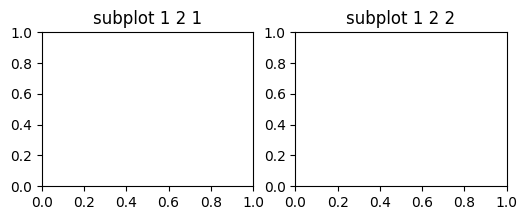

In [3]:
# Формирование двух областей: 1x2
plt.figure("1", figsize=(6, 2))

plt.subplot(1, 2, 1)
plt.title("subplot 1 2 1")

plt.subplot(1, 2, 2)
plt.title("subplot 1 2 2")

plt.show()

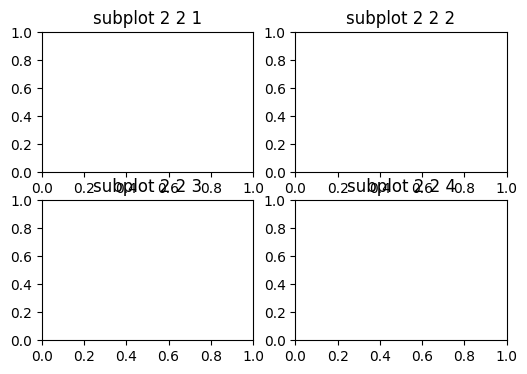

In [4]:
# Формирование четырех областей: 2x2
plt.figure("2",figsize=(6, 4))

plt.subplot(2, 2, 1)
plt.title("subplot 2 2 1")

plt.subplot(2, 2, 2)
plt.title("subplot 2 2 2")

plt.subplot(2, 2, 3)
plt.title("subplot 2 2 3")

plt.subplot(2, 2, 4)
plt.title("subplot 2 2 4")

plt.show()

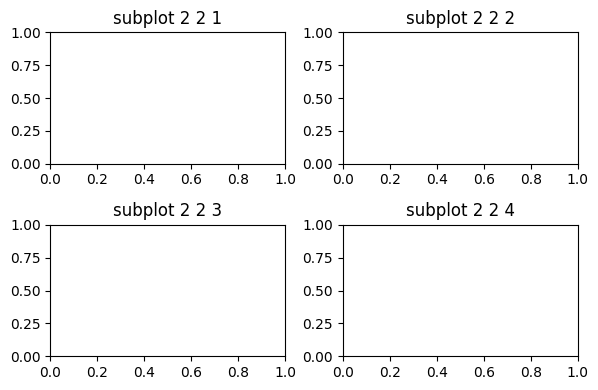

In [5]:
# Корректировка расположения
plt.figure("2",figsize=(6, 4))

plt.subplot(2,2,1)
plt.title("subplot 2 2 1")

plt.subplot(2,2,2)
plt.title("subplot 2 2 2")

plt.subplot(2,2,3)
plt.title("subplot 2 2 3")

plt.subplot(2,2,4)
plt.title("subplot 2 2 4")

plt.tight_layout()

plt.show()

GridSpec(2, 2, height_ratios=[2, 1], width_ratios=[2, 1])


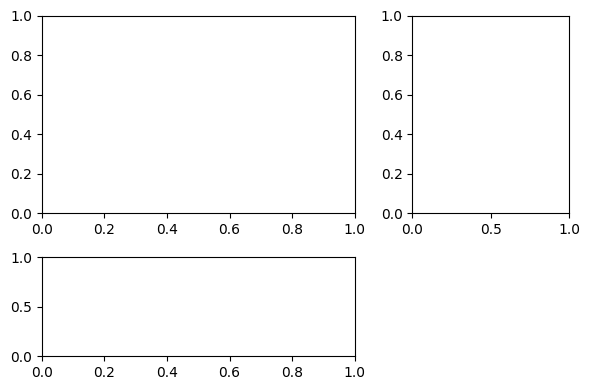

In [6]:
# Использование GridSpec
gs = gridspec.GridSpec(nrows=2, ncols=2, width_ratios=[2, 1], height_ratios=[2, 1])
print(repr(gs))

plt.figure("3",figsize=(6, 4))

plt.subplot(gs[0])
plt.subplot(gs[1])
plt.subplot(gs[2])
# plt.subplot(gs[3])

plt.tight_layout()
plt.show()

## Графики и диаграммы

### Plot

<p>Простой вывод</p>

In [7]:
x = np.arange(start=-2, stop=5, step=1)
x

array([-2, -1,  0,  1,  2,  3,  4])

In [8]:
f = lambda x: x**2

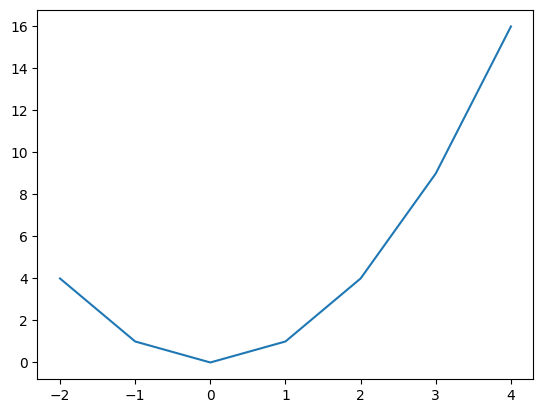

In [9]:
plt.figure("4")
plt.plot(x, f(x))
plt.show()

<p>Способы вывода данных</p>

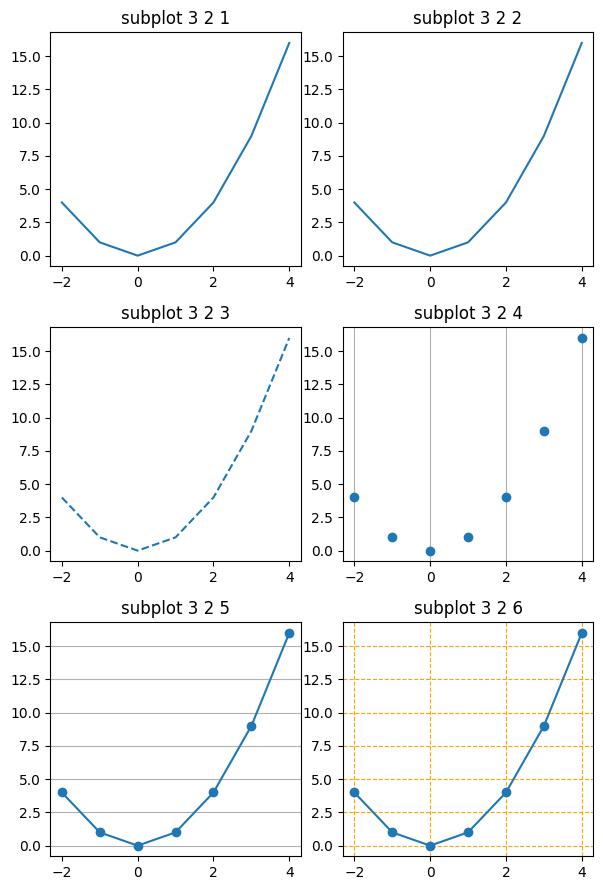

In [10]:
plt.figure("5",figsize=(6, 9))

plt.subplot(3,2,1)
plt.title("subplot 3 2 1")
plt.plot(x, f(x))

plt.subplot(3,2,2)
plt.title("subplot 3 2 2")
plt.plot(x, f(x), "-")

plt.subplot(3,2,3)
plt.title("subplot 3 2 3")
plt.plot(x, f(x), "--")

plt.subplot(3,2,4)
plt.title("subplot 3 2 4")
plt.plot(x, f(x), "o")
plt.grid(True, axis="x")

plt.subplot(3,2,5)
plt.title("subplot 3 2 5")
plt.plot(x, f(x), "o-")
plt.grid(True, axis="y")

plt.subplot(3,2,6)
plt.title("subplot 3 2 6")
plt.plot(x, f(x), "o-")
plt.grid(True, axis="both", color="orange", linestyle="--");

plt.tight_layout()

plt.show()

<p>Оформление вывода данных</p>

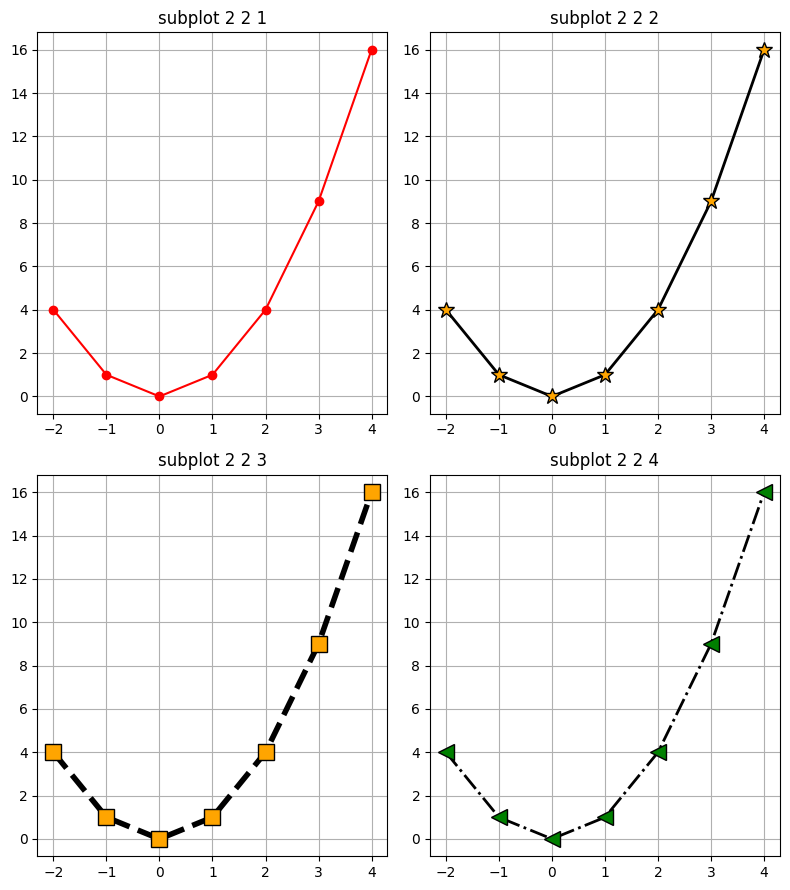

In [11]:
plt.figure("6",figsize=(8, 9))

plt.subplot(2,2,1)
plt.title("subplot 2 2 1")
plt.plot(x, f(x), "-ro")
plt.grid(True)

plt.subplot(2,2,2)
plt.title("subplot 2 2 2")
plt.plot(x, f(x), color="black", linewidth=2, linestyle="solid",
         marker="*", markerfacecolor="orange", markersize=12)
plt.grid(True)

plt.subplot(2,2,3)
plt.title("subplot 2 2 3")
plt.plot(x, f(x), color="black", linewidth=4, linestyle="dashed",
         marker="s", markerfacecolor="orange", markersize=12)
plt.grid(True)

plt.subplot(2,2,4)
plt.title("subplot 2 2 4")
plt.plot(x, f(x), color="black", linewidth=2, linestyle="-.",
         marker="<", markerfacecolor="green", markersize=12)
plt.grid(True)

plt.tight_layout()

plt.show()

<p>Отображение нескольких графиков на одном поле</p>

In [12]:
f1 = lambda x: x**2
f2 = lambda x: x**3

[Настройка шрифта легенды](https://matplotlib.org/3.10.6/api/font_manager_api.html#matplotlib.font_manager.FontProperties)

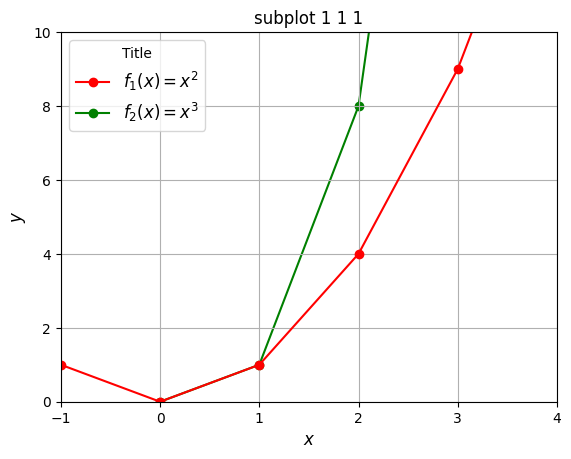

In [13]:
plt.figure("7")

plt.title("subplot 1 1 1")
plt.plot(x, f1(x), "-ro", label="$f_1(x)=x^2$", zorder=2)
plt.plot(x, f2(x), "-go", label="$f_2(x)=x^3$", zorder=1)
plt.grid(True)
plt.axis((-1, 4, 0, 10))
plt.legend(loc=2, title="Title", fontsize=12)
plt.xlabel("$x$", fontsize=12)
plt.ylabel("$y$", fontsize=12)

plt.show()

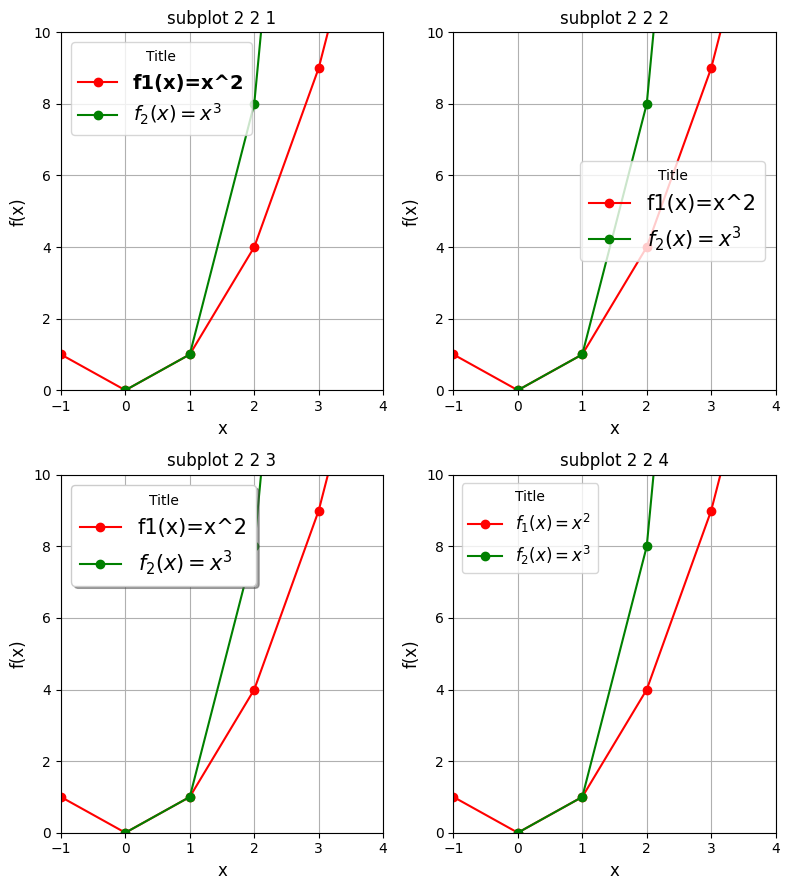

In [14]:
plt.figure("8",figsize=(8, 9))

plt.subplot(2,2,1)
plt.title("subplot 2 2 1")
plt.plot(x, f1(x), "-ro", label="f1(x)=x^2")
plt.plot(x, f2(x), "-go", label="$f_2(x)=x^3$")
plt.xlabel("x", fontsize=12)
plt.ylabel("f(x)", fontsize=12)
plt.grid(True)
plt.axis((-1, 4, 0, 10))
plt.legend(loc=2, prop={"size":14, "weight":"bold"}, title="Title")

plt.subplot(2,2,2)
plt.title("subplot 2 2 2")
plt.plot(x, f1(x), "-ro", label="f1(x)=x^2")
plt.plot(x, f2(x), "-go", label="$f_2(x)=x^3$")
plt.xlabel("x", fontsize=12)
plt.ylabel("f(x)", fontsize=12)
plt.grid(True)
plt.axis((-1, 4, 0, 10))
plt.legend(loc=7, title="Title", fontsize=15)

plt.subplot(2,2,3)
plt.title("subplot 2 2 3")
plt.plot(x, f1(x), "-ro", label="f1(x)=x^2")
plt.plot(x, f2(x), "-go", label="$f_2(x)=x^3$")
plt.xlabel("x", fontsize=12)
plt.ylabel("f(x)", fontsize=12)
plt.grid(True)
plt.axis((-1, 4, 0, 10))
plt.legend(loc=2, title="Title", fontsize=15, shadow=True)

plt.subplot(2,2,4)
plt.title("subplot 2 2 4")
plt.plot(x, f1(x), "-ro", label="$f_1(x)=x^2$")
plt.plot(x, f2(x), "-go", label="$f_2(x)=x^3$")
plt.xlabel("x", fontsize=12)
plt.ylabel("f(x)", fontsize=12)
plt.grid(True)
plt.axis((-1, 4, 0, 10))
plt.legend(loc=2, title="Title", fontsize=12)

plt.tight_layout()

plt.show()

Параметр `axis((-1, 4, 0, 10))` ограничивает видимую область. Часть рассчитанных точек остаётся за пределами рисунка: данные и показанный диапазон нужно проверять отдельно.

<p>Отображение горизонтальных и вертикальных линий</p>

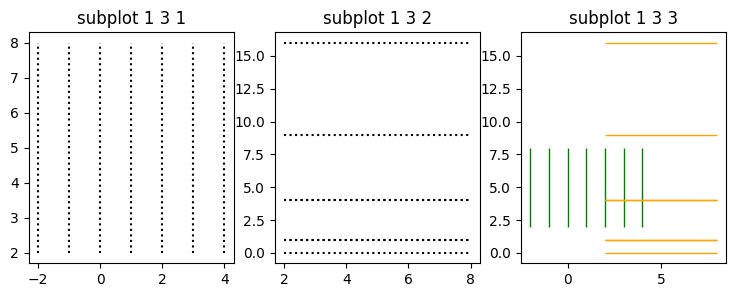

In [15]:
plt.figure("9",figsize=(9, 3))

plt.subplot(1,3,1)
plt.title("subplot 1 3 1")
plt.vlines(x, ymin=2, ymax=8, colors="black", linestyles="dotted")

plt.subplot(1,3,2)
plt.title("subplot 1 3 2")
plt.hlines(f(x), xmin=2, xmax=8, colors="black", linestyles="dotted")

plt.subplot(1,3,3)
plt.title("subplot 1 3 3")
plt.vlines(x, ymin=2, ymax=8, colors="green", linestyles="solid", linewidth=1)
plt.hlines(f(x), xmin=2, xmax=8, colors="orange", linestyles="solid", linewidth=1)

plt.show()

## Scatter

In [16]:
from scipy import stats

In [17]:
x = stats.uniform.rvs(loc=-1, scale=5, size=11, random_state=rng)
y = stats.uniform.rvs(loc=-1, scale=5, size=11, random_state=rng)
x, y

(array([-0.10532593,  2.19956583,  1.33634201,  0.85250264,  0.77458667,
         2.95259123,  3.52571918, -0.11323404,  2.26392401,  0.49151384,
         3.834811  ]),
 array([3.5992508 , 2.17935402, 2.76366049, 1.57576848, 3.12947629,
        1.24190273, 0.69406227, 0.38949608, 0.13166528, 1.62908422,
        1.1545603 ]))

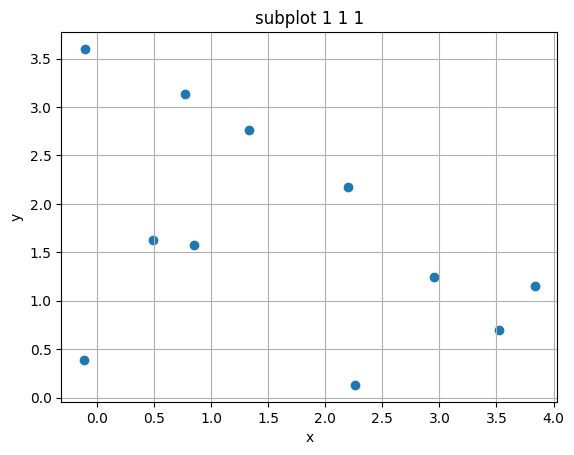

In [18]:
plt.figure("7")

plt.subplot(1,1,1)
plt.title("subplot 1 1 1")
# диаграмма разброса
plt.scatter(x, y)
plt.grid(True)
plt.xlabel("x")
plt.ylabel("y")
plt.show()

<p>Оформление</p>

In [19]:
x1 = stats.uniform.rvs(loc=-1, scale=5, size=11, random_state=rng)
y1 = stats.uniform.rvs(loc=-1, scale=5, size=11, random_state=rng)
x1, y1

(array([ 2.3159031 , -0.93579759,  1.23850951,  0.82590401, -0.023012  ,
         1.97432936,  1.17656578,  0.49995752,  0.04708061,  3.37312029,
         2.98731158]),
 array([2.03354838, 0.72550289, 3.73409895, 1.81688687, 1.1638137 ,
        3.502248  , 0.59670902, 2.47997435, 0.56910164, 0.30776523,
        2.50420445]))

In [20]:
x2 = stats.uniform.rvs(loc=-1, scale=5, size=11, random_state=rng)
f2 = lambda x: x**2
x2, f2(x2)

(array([ 0.13945989,  1.46555161,  1.90014227, -0.05546818,  2.65620329,
         1.74241532,  2.1075163 ,  0.86072158,  1.1009663 ,  1.47414839,
         1.34985456]),
 array([1.94490622e-02, 2.14784154e+00, 3.61054063e+00, 3.07671857e-03,
        7.05541593e+00, 3.03601116e+00, 4.44162495e+00, 7.40841645e-01,
        1.21212679e+00, 2.17311347e+00, 1.82210734e+00]))

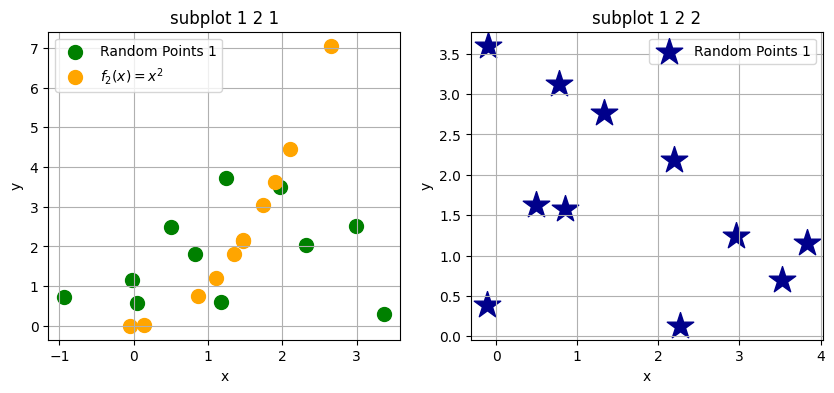

In [21]:
plt.figure("10", figsize=(10, 4))

plt.subplot(1,2,1)
plt.title("subplot 1 2 1")
plt.scatter(x1, y1, marker="o", s=100, label="Random Points 1", color="green")
plt.scatter(x2, f2(x2), marker="o", s=100, label="$f_2(x)=x^2$", color="orange")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()

plt.subplot(1,2,2)
plt.title("subplot 1 2 2")
plt.scatter(x, y, marker="*", s=400, label="Random Points 1", color="darkblue")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True)
plt.legend()

plt.show()

<p>Выделение точек цветом</p>

In [22]:
# from matplotlib import cm
from matplotlib.colors import ListedColormap

In [23]:
clrMap = ListedColormap(["red", "green", "blue"])

In [24]:
z = rng.integers(low=0, high=3, size=11)
z

array([0, 2, 2, 1, 2, 1, 2, 0, 0, 2, 2])

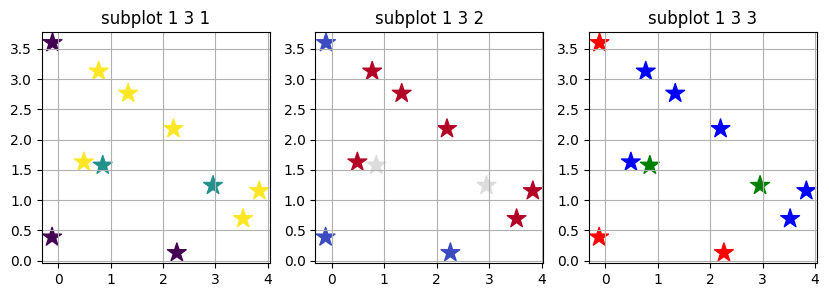

In [25]:
plt.figure("11", figsize=(10, 3))

plt.subplot(1,3,1)
plt.title("subplot 1 3 1")
plt.scatter(x, y, c=z, marker="*", s=200)
plt.grid(True)

plt.subplot(1,3,2)
plt.title("subplot 1 3 2")
plt.scatter(x, y, c=z, marker="*", cmap=plt.colormaps['coolwarm'], s=200)
plt.grid(True)

plt.subplot(1,3,3)
plt.title("subplot 1 3 3")
plt.scatter(x, y, c=z, marker="*", cmap=clrMap, s=200)
plt.grid(True)

plt.show()

### Bar

In [26]:
names = ("A", "B", "C", "D")
offset = np.array([1, 5, 3, 4])
height = np.array([2, 3, 4, 5])

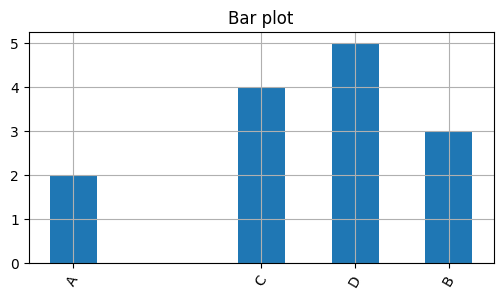

In [27]:
plt.figure("12", figsize=(6, 3))

ax = plt.subplot(1,1,1)
plt.title("Bar plot")
plt.bar(offset, height, width=0.5)
ax.set_xticks(offset)
ax.set_xticklabels(names, rotation=60)

plt.grid(True)
plt.show()

### Histogram

In [28]:
x = stats.norm.rvs(size=1000, random_state=rng)
x[:5]

array([ 1.28807772, -0.55558406, -0.98540383, -1.00295655, -0.96827733])

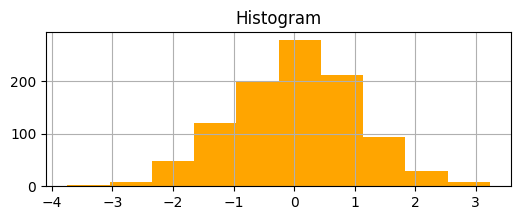

In [29]:
plt.figure("13", figsize=(6, 2))

ax = plt.subplot(1,1,1)
plt.title("Histogram")
plt.hist(x, bins=10, density=False, facecolor="orange")
plt.grid(True)
plt.show()

### Surface

[Трёхмерные поверхности](https://matplotlib.org/3.10.6/api/_as_gen/mpl_toolkits.mplot3d.axes3d.Axes3D.plot_surface.html). Этот и следующий разделы — дополнительные примеры для знакомой из NumPy сетки `meshgrid`.

In [30]:
from matplotlib import cm

Формирование поверхности с использованием meshgrid

In [31]:
# координаты по X и Y
x = [1,2,3]
y = [4,5,6]

In [32]:
# формирование сетки
X, Y = np.meshgrid(x, y)
X

array([[1, 2, 3],
       [1, 2, 3],
       [1, 2, 3]])

In [33]:
Y

array([[4, 4, 4],
       [5, 5, 5],
       [6, 6, 6]])

In [34]:
# получение всех значений функции f(x,y) = x + y
# с учетом введенных значений по координатам X и Y
f = lambda x, y: x + y
f(X,Y)

array([[5, 6, 7],
       [6, 7, 8],
       [7, 8, 9]])

In [35]:
# для f(x,y) = x * y
f = lambda x, y: x * y  # функция
f(X,Y)

array([[ 4,  8, 12],
       [ 5, 10, 15],
       [ 6, 12, 18]])

Построение поверхности

In [36]:
# Формирование сетки
x = np.arange(-20, 20, 0.1)
y = np.arange(-20, 20, 0.1)
X, Y = np.meshgrid(x, y)

# Функция
f = lambda x, y: 2*x**2 + y**2 + x*y

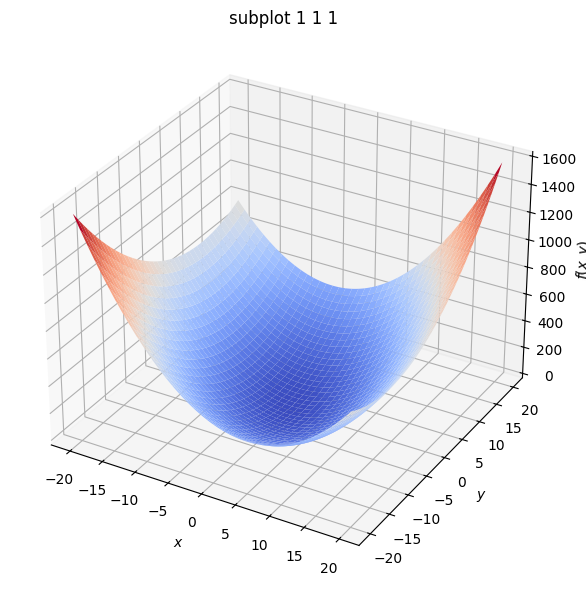

In [37]:
# Отображение поверхности
fig = plt.figure("14", figsize=(6, 6))

ax = fig.add_subplot(1, 1, 1, projection="3d")
ax.plot_surface(X, Y, f(X,Y),
                rstride=10, cstride=10, cmap=cm.coolwarm,
                linewidth=1, antialiased=True)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$f(x,y)$")
ax.set_title("subplot 1 1 1")

plt.tight_layout()

plt.show()

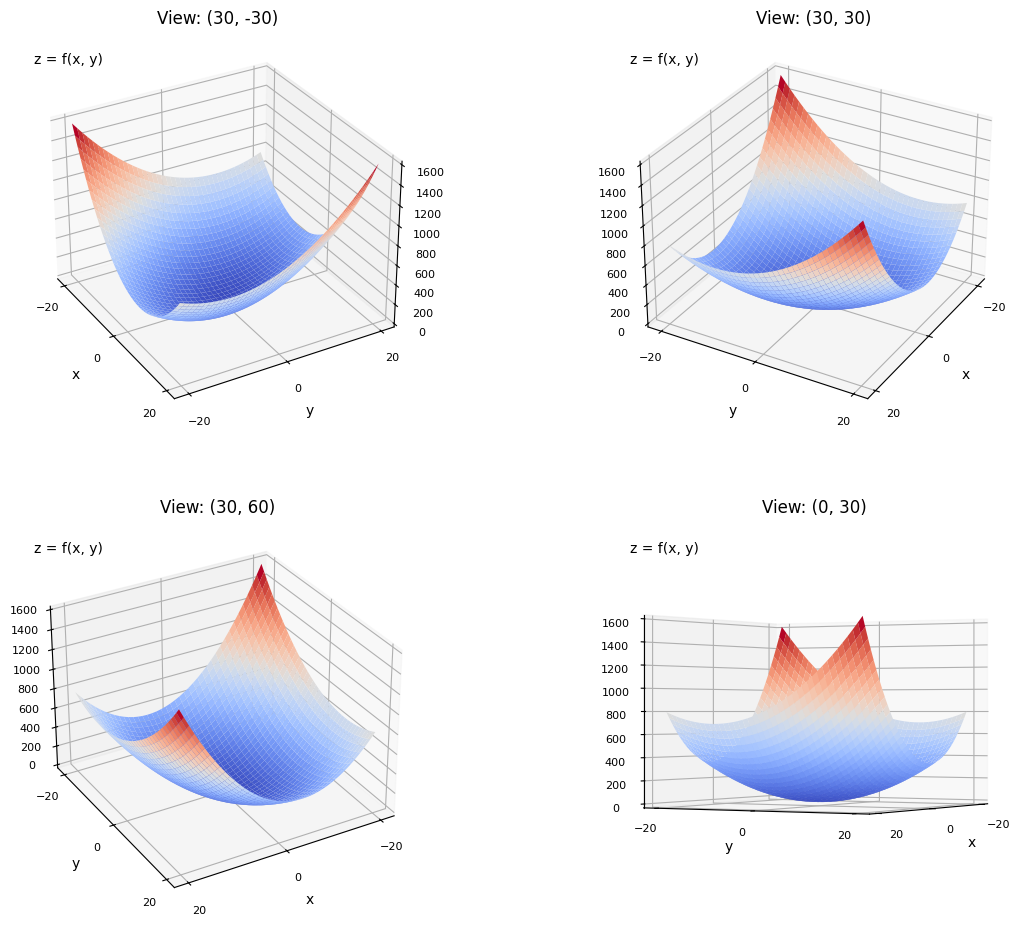

In [38]:
# Отображение поверхности с разных углов

def plot_view(X, Y, Z, ax, view):
    ax.set_title("View: {}".format(view))
    ax.plot_surface(X, Y, Z,
                    rstride=10, cstride=10, cmap=cm.coolwarm,
                    linewidth=1, antialiased=True)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    # Подпись внутри области остаётся видимой при всех ракурсах
    ax.text2D(0.03, 0.92, "z = f(x, y)", transform=ax.transAxes)
    ax.set_xticks([-20, 0, 20])
    ax.set_yticks([-20, 0, 20])
    ax.tick_params(labelsize=8)
    ax.view_init(*view)
    return ax

fig = plt.figure("15", figsize=(12, 10))

views = [(30, -30), (30, 30), (30, 60), (0, 30)]

for indx, view in enumerate(views):
    ax = fig.add_subplot(2, 2, indx+1, projection="3d")
    ax = plot_view(X, Y, f(X,Y), ax=ax, view=view)

fig.subplots_adjust(left=0.08, right=0.92, bottom=0.06, top=0.94,
                    wspace=0.45, hspace=0.25)

plt.show()

### Contour

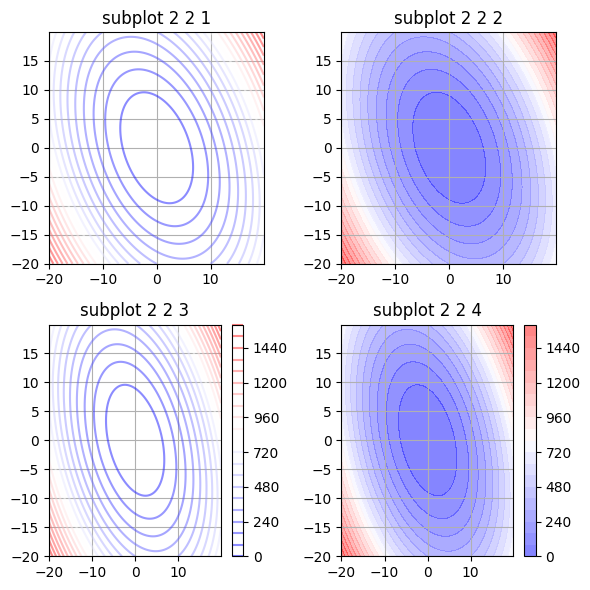

In [39]:
plt.figure("16",figsize=(6, 6))

plt.subplot(2,2,1)
plt.title("subplot 2 2 1")
# контурный график
plt.contour(X, Y, f(X,Y), levels=20, cmap=cm.bwr, alpha=0.5)
plt.grid(True)

plt.subplot(2,2,2)
plt.title("subplot 2 2 2")
plt.contourf(X, Y, f(X,Y), 20, cmap=cm.bwr, alpha=0.5)
plt.grid(True)

plt.subplot(2,2,3)
plt.title("subplot 2 2 3")
plt.contour(X, Y, f(X,Y), 20, cmap=cm.bwr, alpha=0.5)
plt.colorbar()
plt.grid(True)

plt.subplot(2,2,4)
plt.title("subplot 2 2 4")
plt.contourf(X, Y, f(X,Y), 20, cmap=cm.bwr, alpha=0.5)
plt.colorbar()
plt.grid(True)

plt.tight_layout()

plt.show()

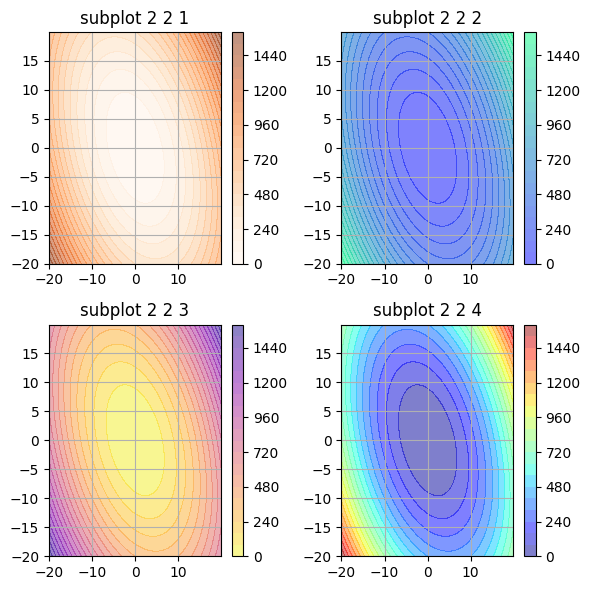

In [40]:
plt.figure("17",figsize=(6, 6))

plt.subplot(2,2,1)
plt.title("subplot 2 2 1")
plt.contourf(X, Y, f(X,Y), 20, cmap=cm.Oranges, alpha=0.5)
plt.colorbar()
plt.grid(True)

plt.subplot(2,2,2)
plt.title("subplot 2 2 2")
plt.contourf(X, Y, f(X,Y), 20, cmap=cm.winter, alpha=0.5)
plt.colorbar()
plt.grid(True)

plt.subplot(2,2,3)
plt.title("subplot 2 2 3")
plt.contourf(X, Y, f(X,Y), 20, cmap=cm.plasma_r, alpha=0.5)
plt.colorbar()
plt.grid(True)

plt.subplot(2,2,4)
plt.title("subplot 2 2 4")
plt.contourf(X, Y, f(X,Y), 20, cmap=cm.jet, alpha=0.5)
plt.colorbar()
plt.grid(True)

plt.tight_layout()

plt.show()

## Доступ к области рисования

Явная ссылка на `Axes` позволяет передать нужную область в функцию. Данные `x` и `y` вычисляются отдельно; функция `plot_function` изменяет переданный объект `ax` и возвращает его. Это управляемый эффект, а не чистое преобразование данных.

Пример с `numpy`

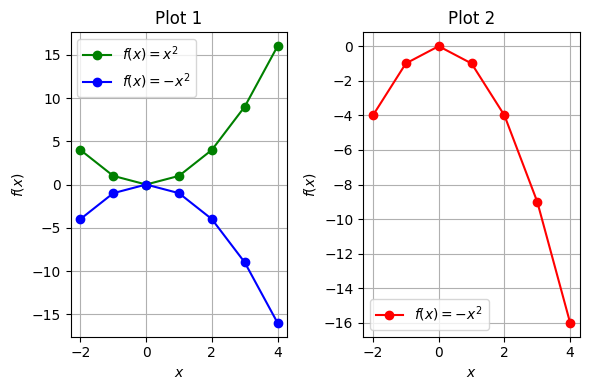

In [41]:
def plot_function(x, y, ax):
    ax.set_title("Plot 2")
    ax.plot(x, y, "-ro", label="$f(x)=-x^2$")
    ax.set_xlabel("$x$")
    ax.set_ylabel("$f(x)$")
    ax.legend()
    return ax

fig, axes = plt.subplots(1, 2, figsize=(6, 4))

x = np.arange(start=-2, stop=5, step=1)
y = x**2

# область 1
axes[0].set_title("Plot 1")
axes[0].plot(x, y, "-go", label="$f(x)=x^2$")
axes[0].plot(x, -y, "-bo", label="$f(x)=-x^2$")
axes[0].set_xlabel("$x$")
axes[0].set_ylabel("$f(x)$")
axes[0].legend()
axes[0].grid(True)

# область 2
axes[1] = plot_function(x, -y, ax=axes[1])
axes[1].grid(True)

fig.tight_layout()

plt.show()

Пример с `pandas`

In [42]:
import pandas as pd

In [43]:
data = rng.integers(0,10, (5, 3))
df = pd.DataFrame(data, columns=["A", "B", "C"])
df.head()

,A,B,C
0,5,4,3
1,3,8,6
2,0,6,8
3,6,0,5
4,5,0,7


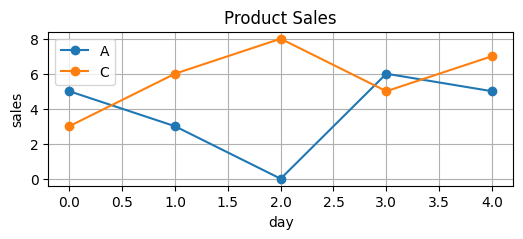

In [44]:
fig, ax = plt.subplots(1, 1, figsize=(6, 2))
ax.set_title("Product Sales")
ax = df[["A", "C"]].plot(marker="o", ax=ax)
ax.grid(True)
ax.set_xlabel("day")
ax.set_ylabel("sales")
plt.show()

## Сохранение в виде рисунка

Сохранение — файловый эффект: `fig.savefig` записывает конкретный рисунок в `plot.png` в текущей рабочей папке ядра. При повторном запуске файл заменяется. Сохраняем рисунок до `show`.

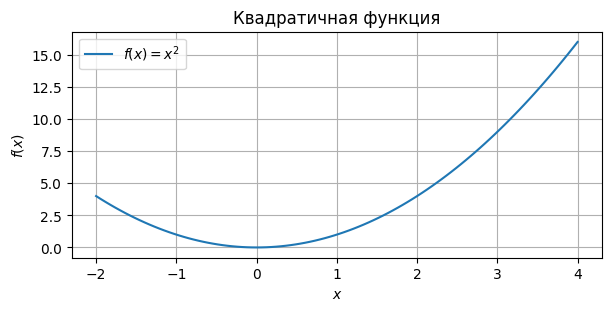

In [45]:
# Независимый пример: не требует запуска дополнительных разделов Surface/Contour
x_export = np.linspace(-2, 4, 100)
y_export = x_export**2

fig, ax = plt.subplots(figsize=(6, 3), layout="constrained")
ax.plot(x_export, y_export, label="$f(x)=x^2$")
ax.set(title="Квадратичная функция", xlabel="$x$", ylabel="$f(x)$")
ax.grid(True)
ax.legend()
fig.savefig("plot.png", dpi=150, bbox_inches="tight")
plt.show()